In [ ]:
import os # Ejecutar comando
import pandas as pd # Manipulacion de data frames
import matplotlib.pyplot as plt # Graficado de datos
import seaborn as sns # Graficar datos
sns.set_theme(style="darkgrid")
import numpy as np # Arreglos y matrices
import plotly.express as px # Graficar datos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Sección nueva

In [ ]:
os.getcwd()

'/content'

In [ ]:
os.chdir('/content/drive/MyDrive/Colab Notebooks/Taller_TopTam')

In [ ]:
os.getcwd()

'/content/drive/MyDrive/Colab Notebooks/Taller_TopTam'

In [ ]:
output_path = 'outputs'
if not os.path.exists(output_path):
    os.mkdir(output_path)

# Exploración de datos
Utilizamos un dataset de temperaturas preprocesado con lecturas de EMAS y MERRA

In [ ]:
temperatures = pd.read_csv('./input_data/RESULT_agg_year_.csv', dtype={"antena":str})
temperatures

,year,Tmax_emas,Tmax_merra,Tmin_emas,Tmin_merra,prec_merra,prec_emas,Evaporacion,antena
0,1980,31.0,29.070770,22.0,22.883120,0.0,0.0,4.85,30018
1,1981,31.0,28.230560,21.5,22.623110,0.0,0.0,4.10,30018
2,1982,31.5,29.089780,22.0,22.874050,0.0,0.0,4.60,30018
3,1983,32.0,28.816010,21.0,22.420470,0.0,0.0,4.30,30018
4,1984,31.0,28.015380,21.0,22.244400,0.0,0.0,3.90,30018
...,...,...,...,...,...,...,...,...,...
144378,2006,NaN,26.097500,NaN,16.392150,0.0,NaN,NaN,30225
144379,2007,NaN,25.948300,NaN,16.026210,0.0,NaN,NaN,30225
144380,2008,NaN,25.416595,NaN,15.972990,0.0,NaN,NaN,30225
144381,2009,NaN,26.119350,NaN,16.535000,0.0,NaN,NaN,30225


In [ ]:
stations = pd.read_csv("./input_data/lista_estaciones_etiquetadas.csv", dtype={"antena":str})
stations

,antena,latitud,longitud,altitud,fuente,hidroregion,topoforma,clima_label,clima_desc,estado
0,3052,27.299,-112.875,150,EMAS,B.C. Centro Oeste,Meseta,BWh,"Arid, desert, hot",Baja California Sur
1,24175,24.284,-100.784,1703,EMAS,El Salado,Llanura,BWh,"Arid, desert, hot",San Luis Potosi
2,30059,22.040,-98.411,12,EMAS,Panuco,Llanura,Aw,"Tropical, savannah",Veracruz
3,17047,19.058,-99.274,2801,EMAS,Balsas,Sierra,Cwb,"Temperate, dry winter, warm summer",Morelos
4,15119,19.470,-99.593,2694,EMAS,Lerma Santiago,Lomerio,Cwb,"Temperate, dry winter, warm summer",Mexico
...,...,...,...,...,...,...,...,...,...,...
4724,CO02,18.340,-114.730,-99,MERRA,NaN,NaN,BWh,"Arid, desert, hot",NaN
4725,19123,25.850,-100.520,-99,MERRA,Bravo Conchos,Valle,BSh,"Arid, steppe, hot",Nuevo Leon
4726,JA05,20.000,-105.130,-99,MERRA,Costa de Jalisco,Valle,Aw,"Tropical, savannah",Jalisco
4727,MC01,20.130,-101.720,-99,MERRA,Lerma Santiago,Sierra,Cwa,"Temperate, dry winter, hot summer",Michoacan


In [ ]:
# Obtenemos un dataset fusionado de antenas y lectura de temperaturas con su clasificación Köppen de climas
temperatures = temperatures.merge(stations, on="antena")
del(stations)
temperatures

,year,Tmax_emas,Tmax_merra,Tmin_emas,Tmin_merra,prec_merra,prec_emas,Evaporacion,antena,latitud,longitud,altitud,fuente,hidroregion,topoforma,clima_label,clima_desc,estado
0,1980,31.0,29.070770,22.0,22.883120,0.0,0.0,4.85,30018,19.157,-96.351,34,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
1,1981,31.0,28.230560,21.5,22.623110,0.0,0.0,4.10,30018,19.157,-96.351,34,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
2,1982,31.5,29.089780,22.0,22.874050,0.0,0.0,4.60,30018,19.157,-96.351,34,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
3,1983,32.0,28.816010,21.0,22.420470,0.0,0.0,4.30,30018,19.157,-96.351,34,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
4,1984,31.0,28.015380,21.0,22.244400,0.0,0.0,3.90,30018,19.157,-96.351,34,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144378,2006,NaN,26.097500,NaN,16.392150,0.0,NaN,NaN,30225,18.975,-96.714,485,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
144379,2007,NaN,25.948300,NaN,16.026210,0.0,NaN,NaN,30225,18.975,-96.714,485,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
144380,2008,NaN,25.416595,NaN,15.972990,0.0,NaN,NaN,30225,18.975,-96.714,485,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz
144381,2009,NaN,26.119350,NaN,16.535000,0.0,NaN,NaN,30225,18.975,-96.714,485,EMAS,Papaloapan,Lomerio,Aw,"Tropical, savannah",Veracruz


In [ ]:
temperatures.sort_values("year").year.unique()

array([1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990,
       1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001,
       2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010])

In [ ]:
conteos = temperatures.groupby('fuente').size().reset_index(name='counts')

In [ ]:
conteos

,fuente,counts
0,EMAS,133347
1,MERRA,11036


In [ ]:
# Transformamos el dataset original para unificar las columnas de temperaturas

emas_temps = temperatures[['year', 'Tmax_emas', 'Tmin_emas']]
aux_max = emas_temps[['year', 'Tmax_emas']].copy().rename(columns={'Tmax_emas':'t'})
aux_max['type'] = 'max'
aux_min = emas_temps[['year', 'Tmin_emas']].copy().rename(columns={'Tmin_emas':'t'})
aux_min['type'] = 'min'
emas_temps = pd.concat([aux_min,aux_max], ignore_index=True)
emas_temps['fuente'] = "emas"
emas_temps

,year,t,type,fuente
0,1980,22.0,min,emas
1,1981,21.5,min,emas
2,1982,22.0,min,emas
3,1983,21.0,min,emas
4,1984,21.0,min,emas
...,...,...,...,...
288761,2006,NaN,max,emas
288762,2007,NaN,max,emas
288763,2008,NaN,max,emas
288764,2009,NaN,max,emas


In [ ]:
merra_temps = temperatures[['year', 'Tmax_merra', 'Tmin_merra']]
aux_max = merra_temps[['year','Tmax_merra']].copy().rename(columns={'Tmax_merra':'t'})
aux_max['type'] = 'max'
aux_min = merra_temps[['year','Tmin_merra']].copy().rename(columns={'Tmin_merra':'t'})
aux_min['type'] = 'min'
merra_temps = pd.concat([aux_min,aux_max], ignore_index=True)
merra_temps['fuente'] = "merra"

In [ ]:
temps = pd.concat([emas_temps,merra_temps], ignore_index=True)
temps

,year,t,type,fuente
0,1980,22.000000,min,emas
1,1981,21.500000,min,emas
2,1982,22.000000,min,emas
3,1983,21.000000,min,emas
4,1984,21.000000,min,emas
...,...,...,...,...
577527,2006,26.097500,max,merra
577528,2007,25.948300,max,merra
577529,2008,25.416595,max,merra
577530,2009,26.119350,max,merra


In [ ]:
# Obtenemos el periodo de los años con los que se cuentan registros
period = temperatures.sort_values("year").year.unique()
period

array([1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990,
       1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001,
       2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010])

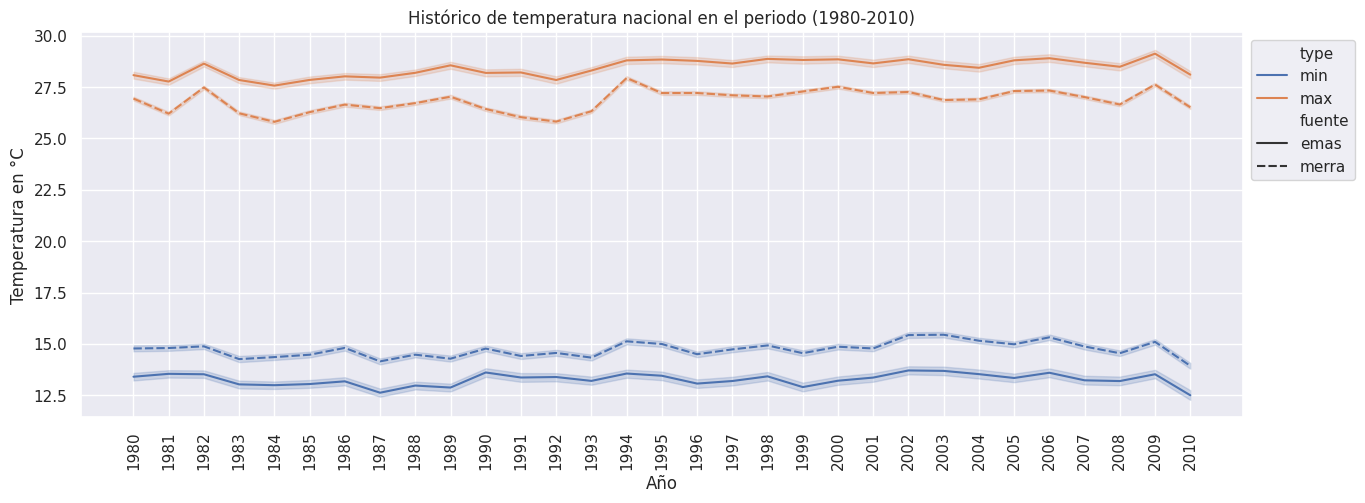

In [ ]:
fig, ax = plt.subplots(figsize=(15,5))
sns.lineplot(temps,
             x="year",
             y="t",
             hue="type",
             style="fuente",
             ax=ax)
ax.set_xticks(period)
ax.set_xlabel("Año")
ax.set_ylabel("Temperatura en °C")
plt.xticks(rotation=90)
ax.legend(loc=2, bbox_to_anchor=(1, 1))
ax.set_title(f"Histórico de temperatura nacional en el periodo ({period.min()}-{period.max()})")
plt.savefig(output_path + "/historico_temperturas.png", bbox_inches='tight')
plt.show()

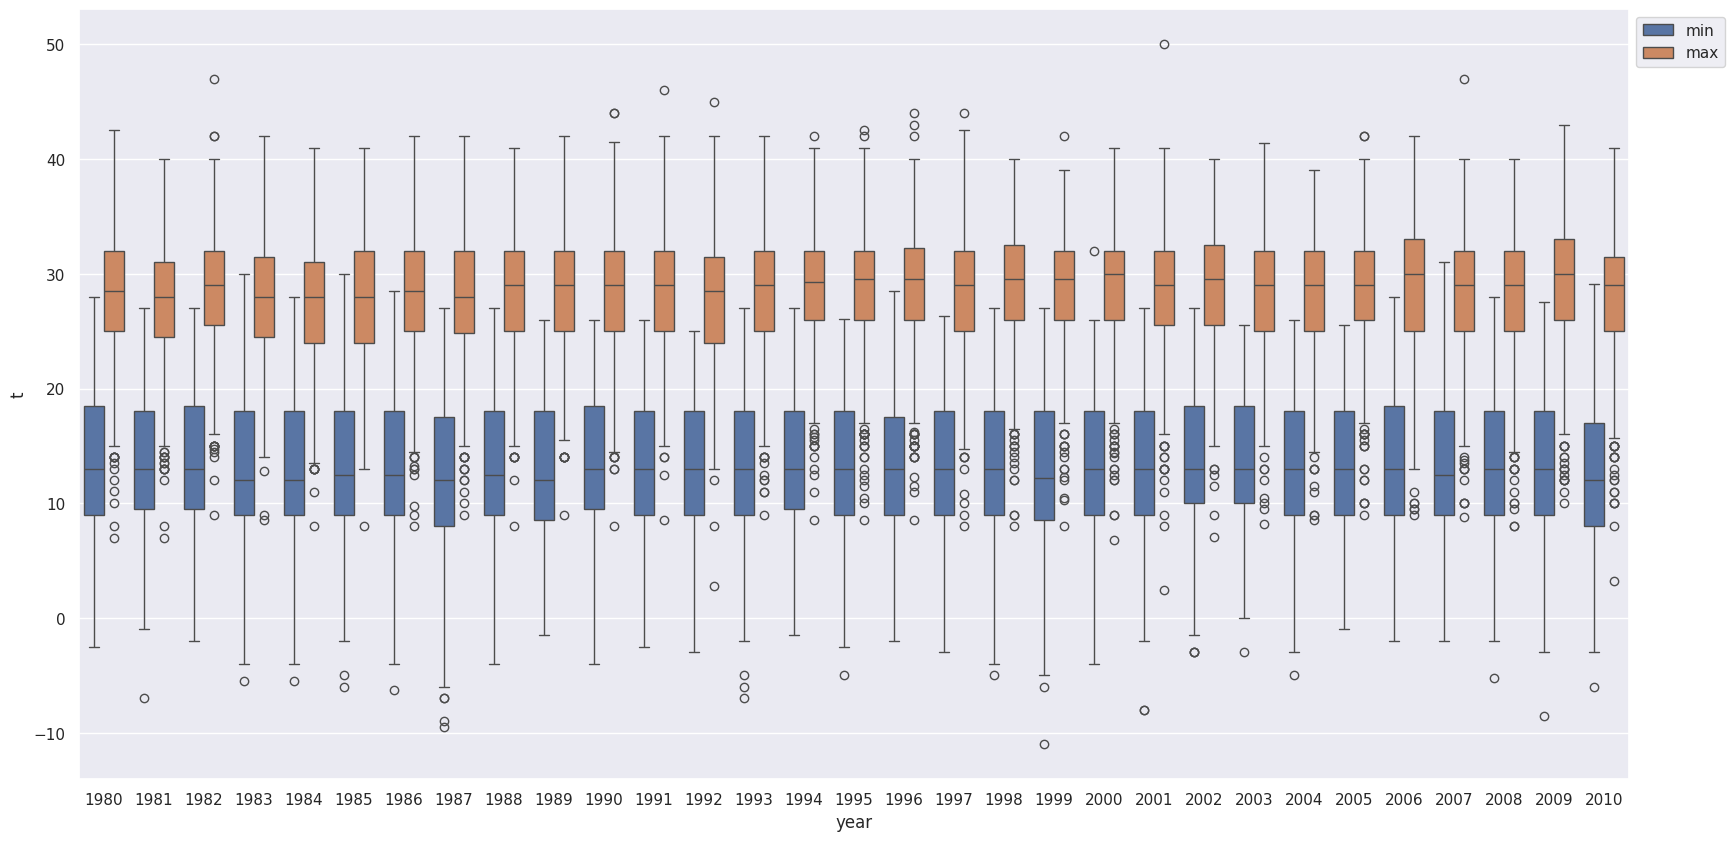

In [ ]:
fig, ax = plt.subplots(figsize=(20,10))
sns.boxplot(temps[temps.fuente=="emas"], x="year", y="t", hue="type", ax=ax)
ax.legend(loc=2, bbox_to_anchor=(1, 1))
plt.savefig(output_path + "/boxplots_emas.png", bbox_inches='tight')
plt.show()

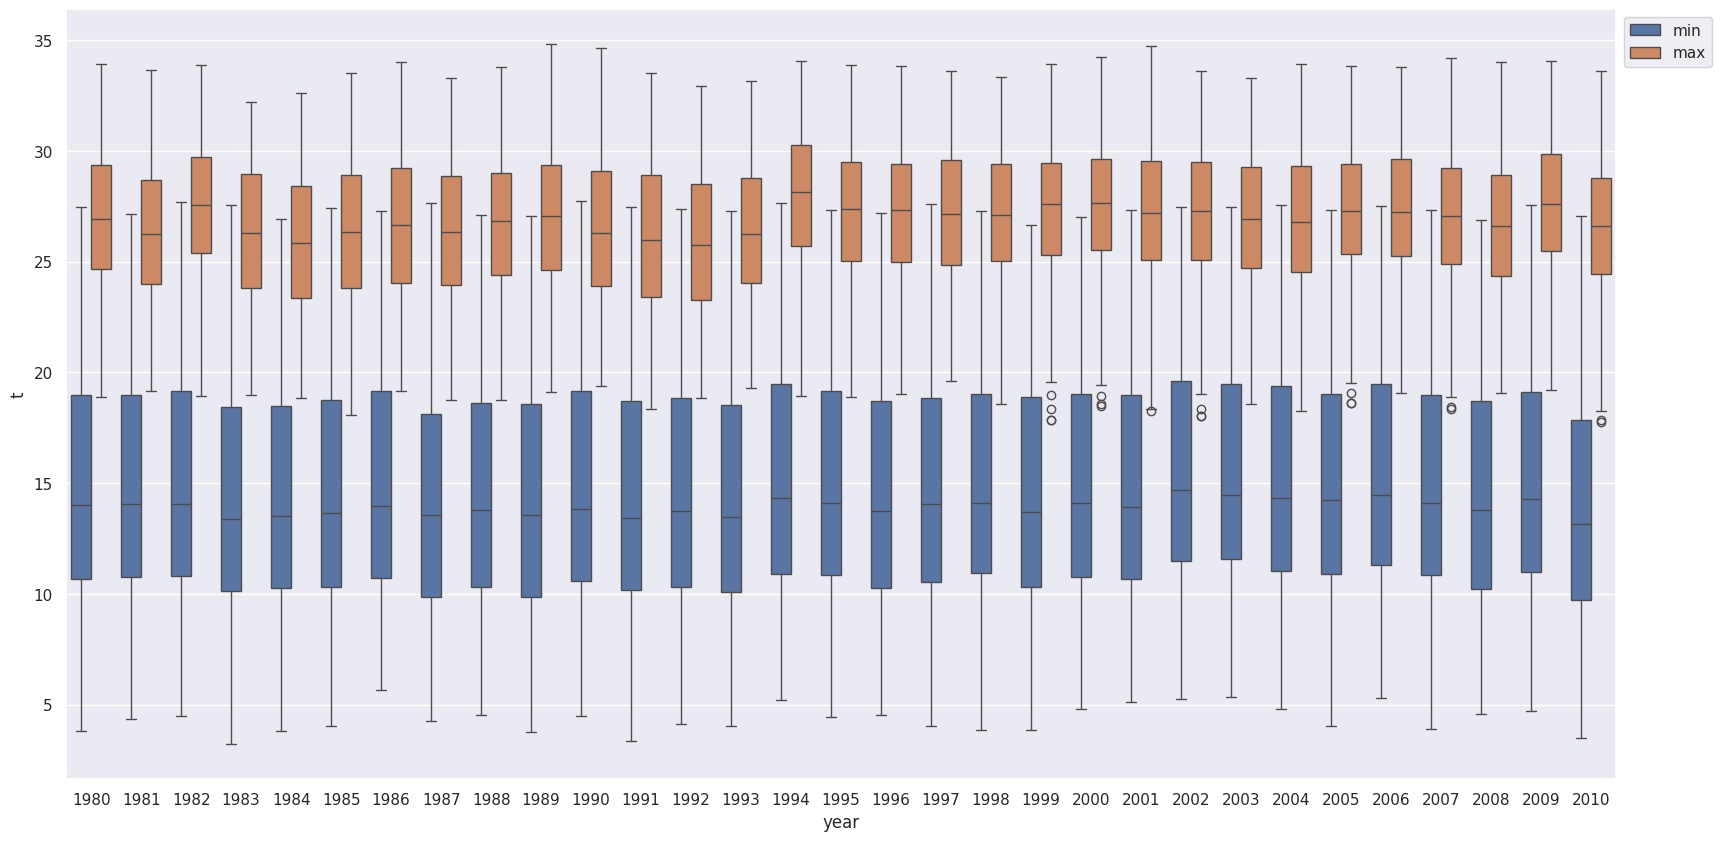

In [ ]:
fig, ax = plt.subplots(figsize=(20,10))
sns.boxplot(temps[temps.fuente=="merra"], x="year", y="t", hue="type", ax=ax)
ax.legend(loc=2, bbox_to_anchor=(1, 1))
plt.savefig(output_path + "/boxplots_merra.png", bbox_inches='tight')
plt.show()

In [ ]:
# Definimos funciones para obtener una tabla de estadisticos

def q25(x):
    return x.quantile(.25)
def q50(x):
    return x.quantile(.50)
def q75(x):
    return x.quantile(.75)
def IQR(x):
    return x.quantile(.75) - x.quantile(.25)
def skew(x):
    return np.median(x) - np.mean(x)
def lower_fence(x):
    lf = q25(x) - (1.5 * IQR(x))
    return np.max([0, lf])
def upper_fence(x):
    return q75(x) + (1.5 * IQR(x))

In [ ]:
temps.columns

Index(['year', 't', 'type', 'fuente'], dtype='object')

In [ ]:
# Generamos la tabla de estadisticos para los boxplot anteriores
stats = temps.groupby(['year', 'type', 'fuente']) \
    .agg({'t':['median', 'min', lower_fence, q25, q50, q75, upper_fence, 'max', IQR]}) \
    ['t'].reset_index()
stats.to_csv(output_path + "/boxplot_statistics.csv", index=False)
stats

,year,type,fuente,median,min,lower_fence,q25,q50,q75,upper_fence,max,IQR
0,1980,max,emas,28.500000,7.000000,14.500000,25.000000,28.500000,32.000000,42.500000,42.500000,7.000000
1,1980,max,merra,26.927720,18.905490,17.648349,24.668608,26.927720,29.348780,36.369039,33.909670,4.680172
2,1980,min,emas,13.000000,-2.500000,0.000000,9.000000,13.000000,18.475000,32.687500,28.000000,9.475000
3,1980,min,merra,14.024200,3.793790,0.000000,10.688342,14.024200,18.998875,31.464674,27.449740,8.310533
4,1981,max,emas,28.000000,7.000000,14.750000,24.500000,28.000000,31.000000,40.750000,40.000000,6.500000
...,...,...,...,...,...,...,...,...,...,...,...,...
119,2009,min,merra,14.299380,4.686770,0.000000,10.983173,14.299380,19.104815,31.287279,27.540920,8.121642
120,2010,max,emas,29.000000,3.200000,15.250000,25.000000,29.000000,31.500000,41.250000,41.000000,6.500000
121,2010,max,merra,26.606985,17.764615,17.966923,24.467734,26.606985,28.801607,35.302418,33.636260,4.333874
122,2010,min,emas,12.000000,-6.000000,0.000000,8.000000,12.000000,17.000000,30.500000,29.100000,9.000000


In [ ]:
# Realizamos un conteo de antenas activas por año para emas

antenas_activas = temperatures[~temperatures.Tmax_emas.isna()].groupby(['year']).size().reset_index(name="counts")
antenas_activas

,year,counts
0,1980,3194
1,1981,3296
2,1982,3477
3,1983,3504
4,1984,3415
5,1985,3285
6,1986,3154
7,1987,3162
8,1988,3019
9,1989,2769


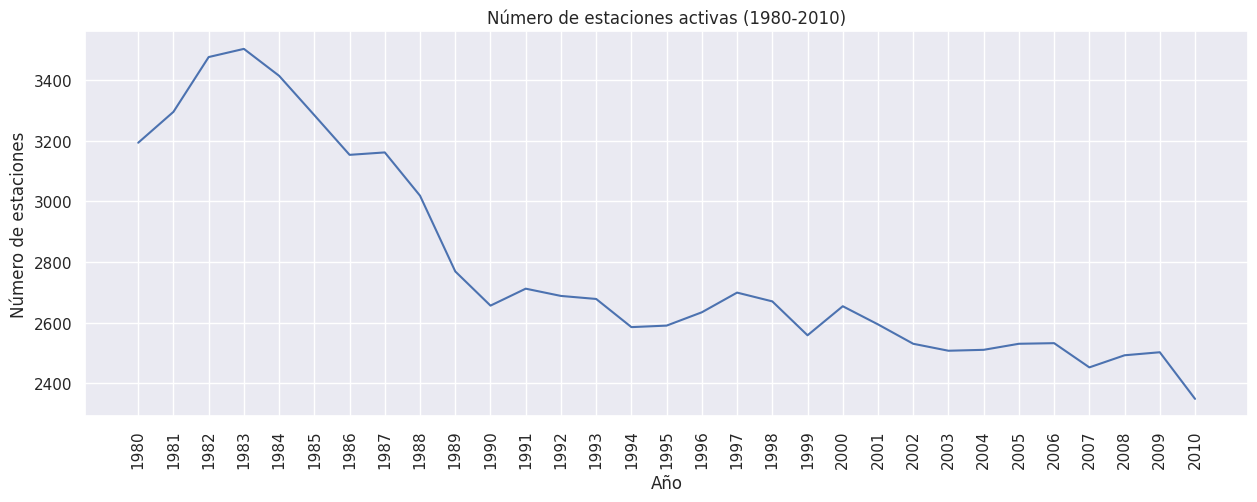

In [ ]:
fig, ax = plt.subplots(figsize=(15,5))
sns.lineplot(antenas_activas,
             x="year",
             y="counts",
             ax=ax)
ax.set_xticks(period)
ax.set_xlabel("Año")
ax.set_ylabel("Número de estaciones")
ax.set_title(f"Número de estaciones activas ({period.min()}-{period.max()})")
plt.xticks(rotation=90)
plt.savefig(output_path + "/estaciones_activas_1980-2010.png", bbox_inches='tight')
plt.show()

In [ ]:
print(f"Max: {antenas_activas['counts'].max()}")
print(f"Min: {antenas_activas['counts'].min()}")

Max: 3504
Min: 2348


In [ ]:
# Identificamos las antenas activas/inactivas para EMAS
ant_act = temperatures[['year','Tmax_emas','clima_desc','antena','estado']].copy()
ant_act['activa'] = True
ant_act['activa'].mask(ant_act.Tmax_emas.isna(), False,inplace=True)
ant_act.head(15)

<ipython-input-56-4939af923c38>:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  ant_act['activa'].mask(ant_act.Tmax_emas.isna(), False,inplace=True)


,year,Tmax_emas,clima_desc,antena,estado,activa
0,1980,31.0,"Tropical, savannah",30018,Veracruz,True
1,1981,31.0,"Tropical, savannah",30018,Veracruz,True
2,1982,31.5,"Tropical, savannah",30018,Veracruz,True
3,1983,32.0,"Tropical, savannah",30018,Veracruz,True
4,1984,31.0,"Tropical, savannah",30018,Veracruz,True
5,1985,32.5,"Tropical, savannah",30018,Veracruz,True
6,1986,31.5,"Tropical, savannah",30018,Veracruz,True
7,1987,31.0,"Tropical, savannah",30018,Veracruz,True
8,1988,32.0,"Tropical, savannah",30018,Veracruz,True
9,1989,NaN,"Tropical, savannah",30018,Veracruz,False


In [ ]:
# Realizamos un conteo de antenas activas por tipo de clima
ant_by_clima = ant_act.groupby(['year','clima_desc','activa']).size().reset_index(name="counts")
ant_by_clima

,year,clima_desc,activa,counts
0,1980,"Arid, desert, cold",False,10
1,1980,"Arid, desert, cold",True,26
2,1980,"Arid, desert, hot",False,162
3,1980,"Arid, desert, hot",True,300
4,1980,"Arid, steppe, cold",False,143
...,...,...,...,...
884,2010,"Tropical, monsoon",True,77
885,2010,"Tropical, rainforest",False,51
886,2010,"Tropical, rainforest",True,37
887,2010,"Tropical, savannah",False,575


In [ ]:
# Generamos una tabla pivote para utilizarla en un heatmap
heat_data = ant_by_clima[ant_by_clima.activa].pivot(index="clima_desc",columns="year",values="counts")
heat_data

year,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010
clima_desc,,,,,,,,,,,,,,,,,,,,,
"Arid, desert, cold",26.0,26.0,25.0,28.0,25.0,21.0,21.0,21.0,18.0,18.0,...,11.0,10.0,11.0,13.0,13.0,13.0,13.0,12.0,12.0,11.0
"Arid, desert, hot",300.0,317.0,338.0,339.0,331.0,324.0,321.0,314.0,301.0,301.0,...,313.0,311.0,313.0,309.0,306.0,302.0,293.0,298.0,288.0,274.0
"Arid, steppe, cold",432.0,443.0,458.0,459.0,439.0,428.0,406.0,407.0,380.0,351.0,...,338.0,342.0,337.0,326.0,335.0,341.0,327.0,313.0,336.0,327.0
"Arid, steppe, hot",506.0,531.0,561.0,566.0,552.0,529.0,488.0,491.0,464.0,449.0,...,465.0,448.0,439.0,436.0,438.0,439.0,385.0,435.0,445.0,386.0
"Polar, frost",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
"Polar, tundra",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0
"Temperate, dry summer, hot summer",6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,5.0,5.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
"Temperate, dry summer, warm summer",17.0,18.0,18.0,18.0,18.0,17.0,13.0,11.0,4.0,4.0,...,2.0,4.0,4.0,4.0,4.0,4.0,4.0,3.0,3.0,3.0
"Temperate, dry winter, hot summer",247.0,258.0,269.0,272.0,273.0,270.0,258.0,266.0,251.0,229.0,...,200.0,200.0,198.0,192.0,183.0,196.0,185.0,179.0,184.0,160.0


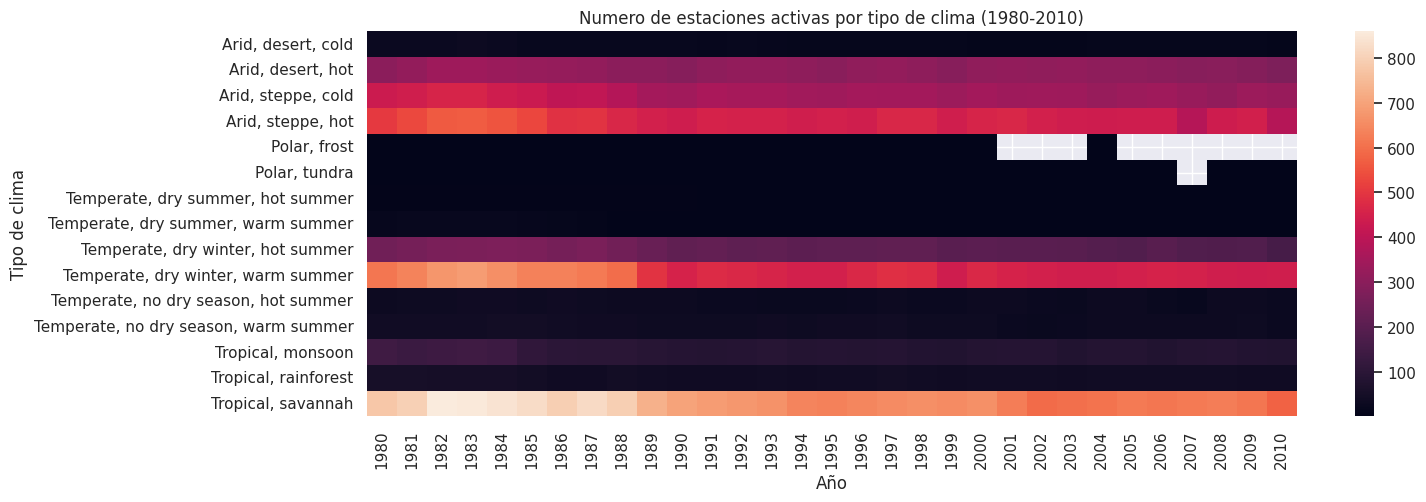

In [ ]:
fig, ax = plt.subplots(figsize=(15,5))
sns.heatmap(heat_data, ax=ax)
ax.set_xlabel("Año")
ax.set_ylabel("Tipo de clima")
ax.set_title(f"Numero de estaciones activas por tipo de clima ({period.min()}-{period.max()})")
plt.show()

In [ ]:
# Realizamos un conteo de antenas activas/inactivas por estado
ant_by_estado = ant_act.groupby(['year','estado','activa']).size().reset_index(name="counts")
ant_by_estado

,year,estado,activa,counts
0,1980,Aguascalientes,False,19
1,1980,Aguascalientes,True,51
2,1980,Baja California,False,41
3,1980,Baja California,True,85
4,1980,Baja California Sur,False,36
...,...,...,...,...
1979,2010,Veracruz,True,116
1980,2010,Yucatan,False,31
1981,2010,Yucatan,True,48
1982,2010,Zacatecas,False,24


In [ ]:
# Generamos una tabla pivote para las antenas por activas por estado para utilizarla en un heatmap
heat_data = ant_by_estado[ant_by_estado.activa].pivot(index="estado",columns="year",values="counts")
heat_data

year,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010
estado,,,,,,,,,,,,,,,,,,,,,
Aguascalientes,51,53,53,54,52,53,55,55,57,53,...,58,58,58,58,57,58,56,57,57,58
Baja California,85,91,101,99,90,88,94,83,82,90,...,72,71,70,71,70,68,65,64,65,66
Baja California Sur,101,100,105,105,100,99,102,103,101,97,...,109,110,112,112,112,111,112,112,112,112
Campeche,30,32,38,39,40,40,40,40,39,40,...,44,43,45,45,46,46,46,46,46,46
Chiapas,55,54,55,54,47,47,45,54,55,48,...,42,40,41,41,39,41,39,39,40,39
Chihuahua,161,165,164,166,155,134,128,126,65,60,...,34,40,47,45,45,45,45,41,39,41
Coahuila,54,65,68,68,72,74,65,72,70,72,...,71,72,71,71,71,69,74,70,66,59
Colima,25,26,26,26,35,36,30,36,35,34,...,30,30,30,30,31,31,32,30,30,30
Distrito Federal,32,30,32,32,31,31,29,27,26,11,...,13,14,14,14,15,15,16,15,2,14


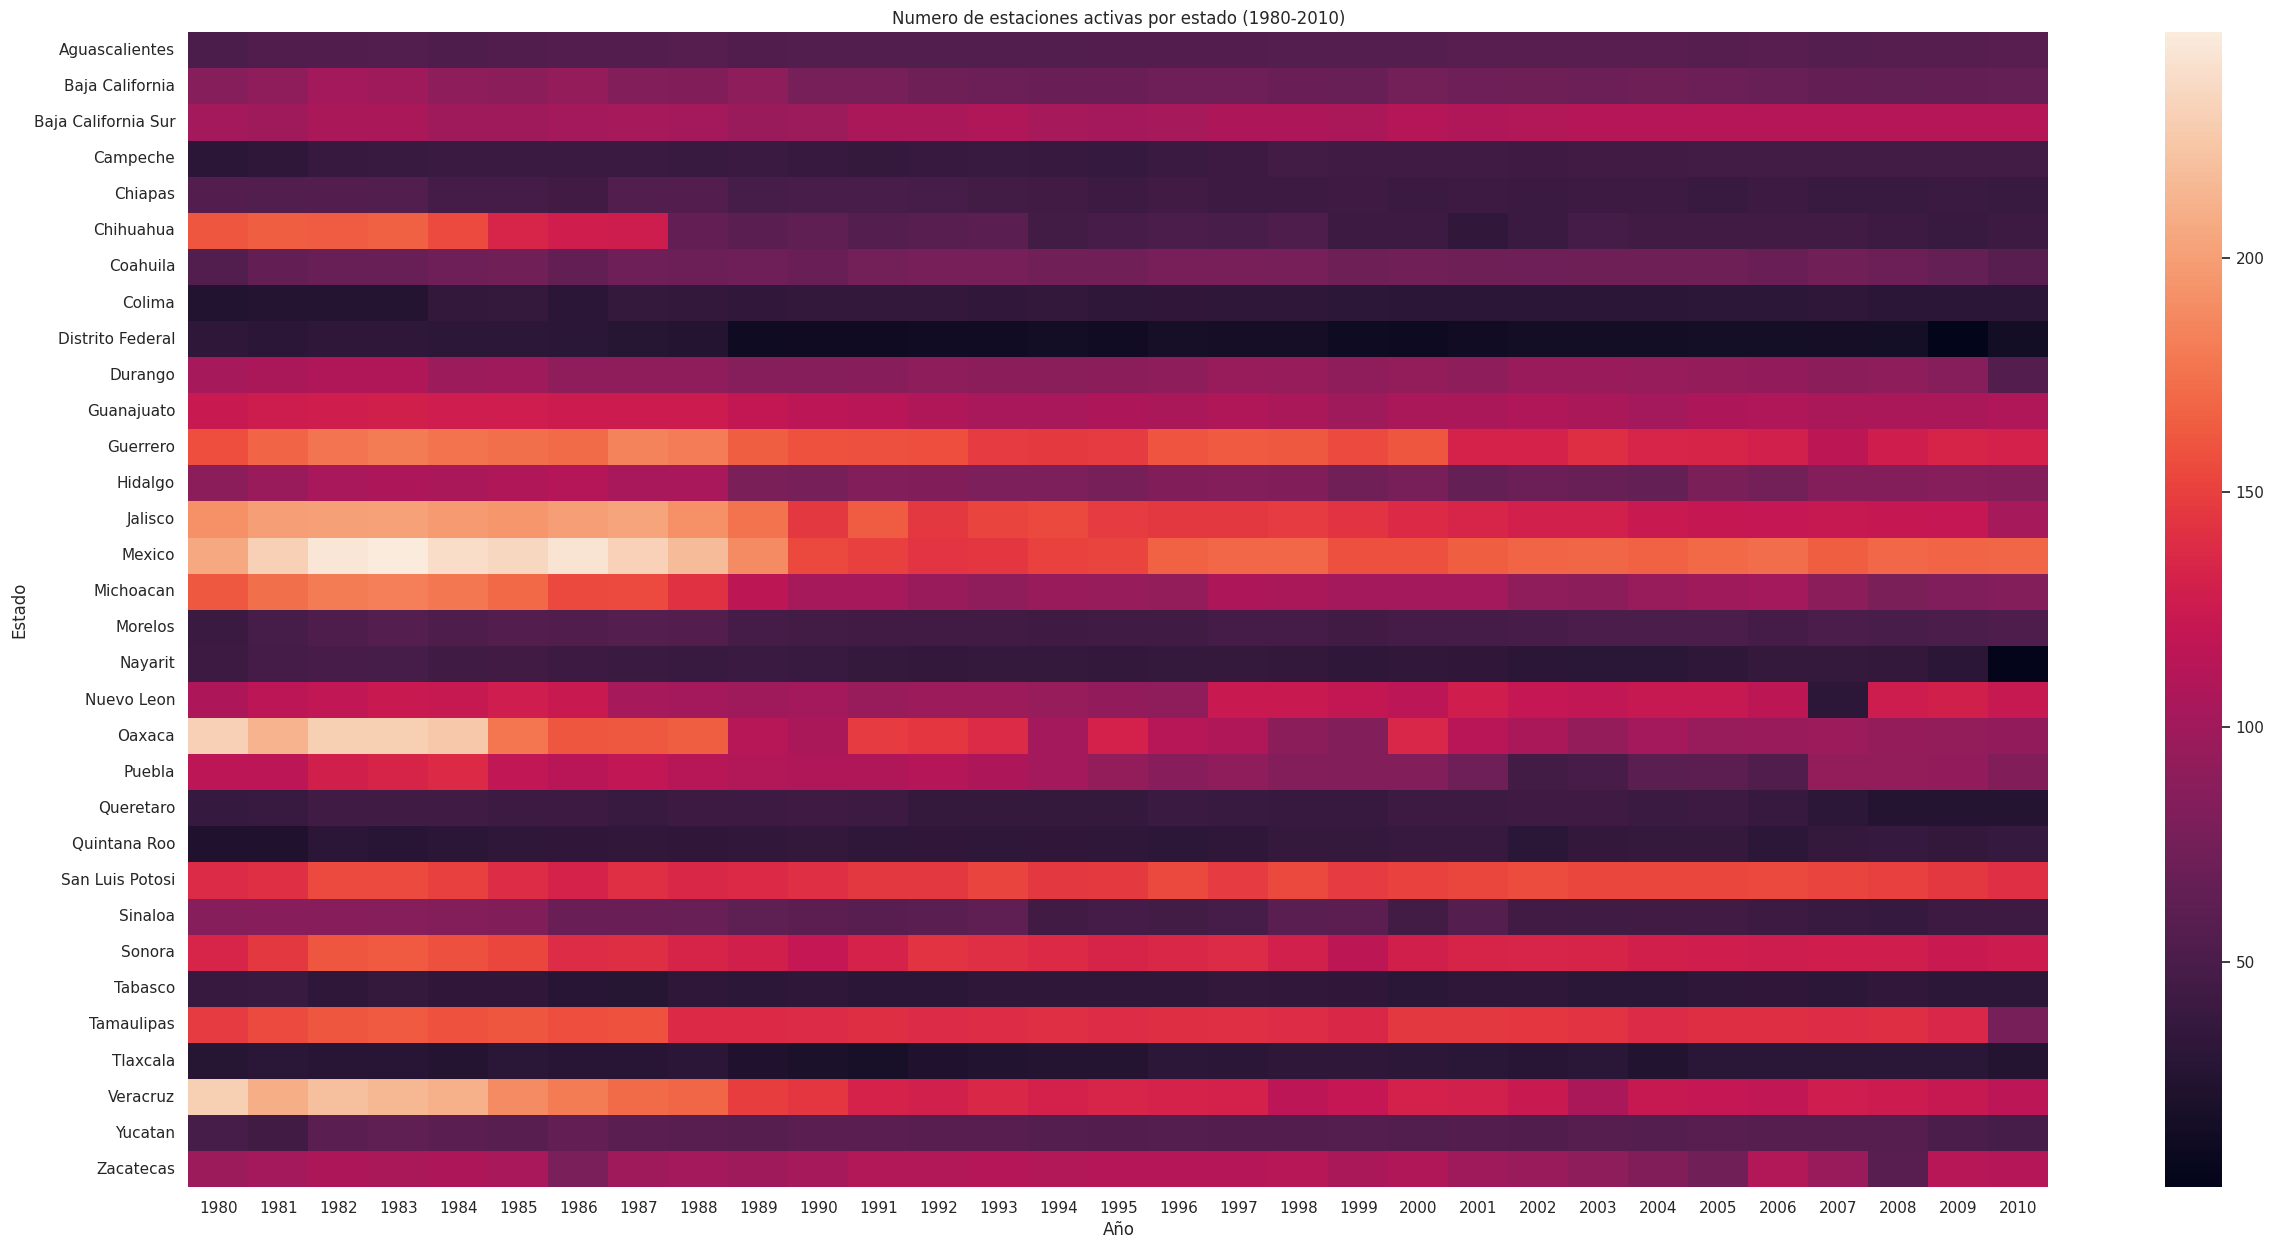

In [ ]:
fig, ax = plt.subplots(figsize=(30,15))
sns.heatmap(heat_data, ax=ax)
ax.set_xlabel("Año")
ax.set_ylabel("Estado")
ax.set_title(f"Numero de estaciones activas por estado ({period.min()}-{period.max()})")
plt.show()

# Clasificación
## Preprocesamiento de datos

In [ ]:
# Realizamos un filtrado de datos nulos tomando solo aquellos registros que tienen una lectura de temperatura y etiqueta de clase
classification_data = temperatures[(~temperatures.Tmax_merra.isna()) &
             (~temperatures.Tmin_merra.isna()) &
             (~temperatures.clima_label.isna())].copy()
classification_data.shape

(142011, 18)

In [ ]:
classification_data.columns

Index(['year', 'Tmax_emas', 'Tmax_merra', 'Tmin_emas', 'Tmin_merra',
       'prec_merra', 'prec_emas', 'Evaporacion', 'antena', 'latitud',
       'longitud', 'altitud', 'fuente', 'hidroregion', 'topoforma',
       'clima_label', 'clima_desc', 'estado'],
      dtype='object')

In [ ]:
# Eliminamos columnas que no son de interes para este ejercicio
classification_data = classification_data.drop(['Tmax_emas', 'Tmin_emas','prec_merra', 'prec_emas', 'Evaporacion',
                                                'altitud', 'fuente', 'hidroregion', 'topoforma','estado'], axis=1)

In [ ]:
classification_data

,year,Tmax_merra,Tmin_merra,antena,latitud,longitud,clima_label,clima_desc
0,1980,29.070770,22.883120,30018,19.157,-96.351,Aw,"Tropical, savannah"
1,1981,28.230560,22.623110,30018,19.157,-96.351,Aw,"Tropical, savannah"
2,1982,29.089780,22.874050,30018,19.157,-96.351,Aw,"Tropical, savannah"
3,1983,28.816010,22.420470,30018,19.157,-96.351,Aw,"Tropical, savannah"
4,1984,28.015380,22.244400,30018,19.157,-96.351,Aw,"Tropical, savannah"
...,...,...,...,...,...,...,...,...
144378,2006,26.097500,16.392150,30225,18.975,-96.714,Aw,"Tropical, savannah"
144379,2007,25.948300,16.026210,30225,18.975,-96.714,Aw,"Tropical, savannah"
144380,2008,25.416595,15.972990,30225,18.975,-96.714,Aw,"Tropical, savannah"
144381,2009,26.119350,16.535000,30225,18.975,-96.714,Aw,"Tropical, savannah"


In [ ]:
# Visualizamos los diferentes tipos de clima que existen en la base de datos
classification_data[['clima_label','clima_desc']].drop_duplicates().sort_values("clima_label")

,clima_label,clima_desc
155,Af,"Tropical, rainforest"
527,Am,"Tropical, monsoon"
0,Aw,"Tropical, savannah"
372,BSh,"Arid, steppe, hot"
124,BSk,"Arid, steppe, cold"
62,BWh,"Arid, desert, hot"
3470,BWk,"Arid, desert, cold"
310,Cfa,"Temperate, no dry season, hot summer"
6904,Cfb,"Temperate, no dry season, warm summer"
10439,Csa,"Temperate, dry summer, hot summer"


In [ ]:
# Creamos una etiqueta simple de la clasificacion Koppen Geiger
classification_data['clima_label_simp'] = classification_data.clima_label.str[0]
classification_data

,year,Tmax_merra,Tmin_merra,antena,latitud,longitud,clima_label,clima_desc,clima_label_simp
0,1980,29.070770,22.883120,30018,19.157,-96.351,Aw,"Tropical, savannah",A
1,1981,28.230560,22.623110,30018,19.157,-96.351,Aw,"Tropical, savannah",A
2,1982,29.089780,22.874050,30018,19.157,-96.351,Aw,"Tropical, savannah",A
3,1983,28.816010,22.420470,30018,19.157,-96.351,Aw,"Tropical, savannah",A
4,1984,28.015380,22.244400,30018,19.157,-96.351,Aw,"Tropical, savannah",A
...,...,...,...,...,...,...,...,...,...
144378,2006,26.097500,16.392150,30225,18.975,-96.714,Aw,"Tropical, savannah",A
144379,2007,25.948300,16.026210,30225,18.975,-96.714,Aw,"Tropical, savannah",A
144380,2008,25.416595,15.972990,30225,18.975,-96.714,Aw,"Tropical, savannah",A
144381,2009,26.119350,16.535000,30225,18.975,-96.714,Aw,"Tropical, savannah",A


In [ ]:
# Visualizamos las antenas de nuestro dataset en un mapa
fig = px.scatter_mapbox(classification_data[classification_data.year==2010].sort_values("clima_label"),
                        lat="latitud",
                        lon="longitud",
                        color="clima_label_simp",
                        hover_name="antena",
                        hover_data=['Tmax_merra','Tmin_merra','latitud','longitud'],
                        height=720,
                        # animation_frame="year",
                        zoom=3,
                        center={"lat":22.3969, "lon": -101.2833},
                        mapbox_style="carto-positron")
fig.show()

## Preprocesamiento de datos

In [ ]:
# Normalización de datos
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

In [ ]:
scaler = MinMaxScaler()

In [ ]:
# Normalizamos los registros de temperaturas entre 0 y 1
classification_data['Tmax_merra'] = scaler.fit_transform(np.array(classification_data.Tmax_merra).reshape(-1,1))
classification_data['Tmin_merra'] = scaler.fit_transform(np.array(classification_data.Tmin_merra).reshape(-1,1))
classification_data

,year,Tmax_merra,Tmin_merra,antena,latitud,longitud,clima_label,clima_desc,clima_label_simp
0,1980,0.662794,0.852316,30018,19.157,-96.351,Aw,"Tropical, savannah",A
1,1981,0.613539,0.841055,30018,19.157,-96.351,Aw,"Tropical, savannah",A
2,1982,0.663908,0.851924,30018,19.157,-96.351,Aw,"Tropical, savannah",A
3,1983,0.647859,0.832278,30018,19.157,-96.351,Aw,"Tropical, savannah",A
4,1984,0.600924,0.824652,30018,19.157,-96.351,Aw,"Tropical, savannah",A
...,...,...,...,...,...,...,...,...,...
144378,2006,0.488494,0.571177,30225,18.975,-96.714,Aw,"Tropical, savannah",A
144379,2007,0.479747,0.555327,30225,18.975,-96.714,Aw,"Tropical, savannah",A
144380,2008,0.448577,0.553022,30225,18.975,-96.714,Aw,"Tropical, savannah",A
144381,2009,0.489775,0.577364,30225,18.975,-96.714,Aw,"Tropical, savannah",A


In [ ]:
classification_data['clima_label_simp'].unique()

array(['A', 'B', 'C', 'E'], dtype=object)

In [ ]:
# Transformamos las etiquetas simplificadas en una representación One-Hot-Encoding
encoder = OneHotEncoder()
y = encoder.fit_transform(np.array(classification_data.clima_label_simp).reshape(-1,1)).toarray()

In [ ]:
y

array([[1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       ...,
       [1., 0., 0., 0.],
       [1., 0., 0., 0.],
       [1., 0., 0., 0.]])

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Partimos el dataset en subconjuntos de enrenamiento, validación y prueba
X_train, X_test, y_train, y_test = train_test_split(classification_data[['Tmax_merra','Tmin_merra']],
                                                    y,
                                                    test_size=0.20,
                                                    shuffle=True)

In [ ]:
X_validation, X_test, y_validation, y_test = train_test_split(X_test,
                                                    y_test,
                                                    test_size=0.50,
                                                    shuffle=True)

In [ ]:
print(X_train.shape)
print(X_validation.shape)
print(X_test.shape)
print(y_train.shape)
print(y_validation.shape)
print(y_test.shape)

(113608, 2)
(14201, 2)
(14202, 2)
(113608, 4)
(14201, 4)
(14202, 4)


## Entrenamiento de una red neuronal artificial

In [ ]:
# Realizamos la definición del modelo de red neuronal
model = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Dense(128, activation='relu', name="oculta_1"),
    tf.keras.layers.Dense(4, activation="softmax", name="salida")
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                     │ (None, 128)                 │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ salida (Dense)                       │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 900 (3.52 KB)

 Trainable params: 900 (3.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.CategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
epocas = 10

In [ ]:
# Realizamos el entrenamiento de la red neuronal
history = model.fit(x=X_train,
                    y=y_train,
                    validation_data=(X_validation,y_validation),
                    shuffle=True,
                    epochs=epocas)

Epoch 1/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step - accuracy: 0.6249 - loss: 0.8233 - val_accuracy: 0.7106 - val_loss: 0.6637
Epoch 2/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.7067 - loss: 0.6662 - val_accuracy: 0.7236 - val_loss: 0.6387
Epoch 3/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step - accuracy: 0.7199 - loss: 0.6486 - val_accuracy: 0.7295 - val_loss: 0.6284
Epoch 4/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.7274 - loss: 0.6359 - val_accuracy: 0.7334 - val_loss: 0.6218
Epoch 5/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.7278 - loss: 0.6311 - val_accuracy: 0.7354 - val_loss: 0.6198
Epoch 6/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step - accuracy: 0.7320 - loss: 0.6251 - val_accuracy: 0.7364 - val_loss: 0.6164
Epoch 7/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step - accuracy: 0.7307 - loss: 0.6244 - val_accuracy: 0.7331 - val_loss: 0.6239
Epoch 8/10
3551/3551 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.7331 - loss: 0.6207 

In [ ]:
pd.DataFrame(history.history)

,accuracy,loss,val_accuracy,val_loss
0,0.673474,0.723622,0.710584,0.663718
1,0.711543,0.659014,0.723611,0.638677
2,0.723523,0.641494,0.729526,0.628364
3,0.727695,0.632672,0.733399,0.621826
4,0.728619,0.627852,0.735441,0.619829
5,0.730961,0.624884,0.736427,0.616369
6,0.732105,0.622926,0.733117,0.623902
7,0.732598,0.621478,0.733258,0.614384
8,0.732792,0.619984,0.735089,0.613504
9,0.732827,0.618050,0.733329,0.614900


In [ ]:
# Transformamos los datos del historial de rendimiento para visualizarlos posteriormente
historial = pd.DataFrame(history.history)[['accuracy','loss']].copy()
historial["data_set"] = "Entrenamiento"
historial['epoca'] = np.arange(epocas)
aux = pd.DataFrame(history.history)[['val_accuracy','val_loss']].copy().rename(columns={'val_accuracy':'accuracy','val_loss':'loss'})
aux["data_set"] = "Validacion"
aux['epoca'] = np.arange(epocas)
historial = pd.concat([historial,aux], ignore_index=True)
historial

,accuracy,loss,data_set,epoca
0,0.673474,0.723622,Entrenamiento,0
1,0.711543,0.659014,Entrenamiento,1
2,0.723523,0.641494,Entrenamiento,2
3,0.727695,0.632672,Entrenamiento,3
4,0.728619,0.627852,Entrenamiento,4
5,0.730961,0.624884,Entrenamiento,5
6,0.732105,0.622926,Entrenamiento,6
7,0.732598,0.621478,Entrenamiento,7
8,0.732792,0.619984,Entrenamiento,8
9,0.732827,0.618050,Entrenamiento,9


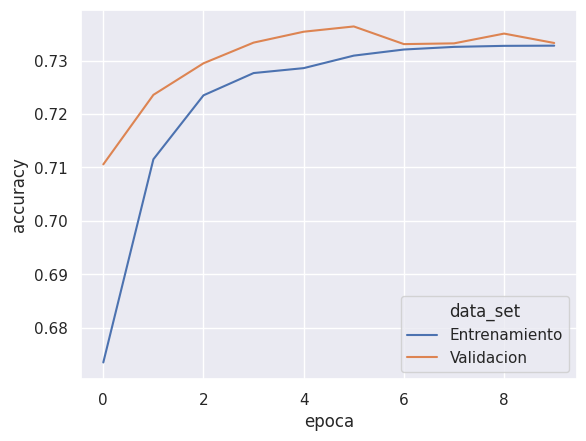

In [ ]:
fig, ax = plt.subplots()#figsize=(10,5))
sns.lineplot(historial, x="epoca", y="accuracy", hue="data_set", ax=ax)
plt.show()

In [ ]:
# Evaluamos el modelo con el conjunto de prueba
test_loss, test_acc = model.evaluate(X_test,  y_test, verbose=2)

print('\nTest accuracy:', test_acc)

444/444 - 1s - 2ms/step - accuracy: 0.7291 - loss: 0.6179

Test accuracy: 0.7290522456169128


In [ ]:
# Realizamos predicciones con los datos de prueba
predictions = model.predict(X_test)

444/444 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [ ]:
predictions

array([[7.4819314e-01, 1.4673087e-01, 1.0507608e-01, 1.2029563e-08],
       [1.9760197e-03, 9.9250710e-01, 5.5169994e-03, 3.7153185e-13],
       [6.3427430e-01, 2.4964279e-01, 1.1608287e-01, 1.0187887e-08],
       ...,
       [2.9505951e-05, 6.1457348e-01, 3.8510403e-01, 2.9299225e-04],
       [2.8136783e-04, 9.9299353e-01, 6.7251129e-03, 3.5252995e-11],
       [9.4487458e-01, 4.8684616e-02, 6.4407662e-03, 1.0790446e-13]],
      dtype=float32)

In [ ]:
np.argmax(predictions,axis=1)

array([0, 1, 0, ..., 1, 1, 0])

In [ ]:
encoder.inverse_transform(predictions)

array([['A'],
       ['B'],
       ['A'],
       ...,
       ['B'],
       ['B'],
       ['A']], dtype=object)

In [ ]:
encoder.inverse_transform(y_test)

array([['A'],
       ['B'],
       ['A'],
       ...,
       ['B'],
       ['B'],
       ['A']], dtype=object)